# Mock fit 1: photometry

A galaxy seen in twelve broad bands from the far ultraviolet to the mid infrared, nothing
else. The notebook builds the forward model, draws mock fluxes from one set of input
parameters, fits them with nested sampling and compares the posterior with the input,
including the star-formation history and two derived quantities.

On an Apple Silicon Mac with `pip install ceridwen` (macOS 26, Python 3.12 or newer) the fit
runs on the GPU in float32; `import ceridwen` sees the GPU and says so. Elsewhere the same
cells run in float64 on the CPU or an NVIDIA GPU. What float32 mode guarantees is in
`docs/mac_gpu.md`.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

import ceridwen                                   # on a Mac with jax-graft: the GPU, float32 mode
from ceridwen import SSPData, CSPBasis, SedModel, fitSED, PostProcess
from ceridwen.observation import Photometry, Spectrum, Lines
from ceridwen.broadening import Instrument, Kinematics
from ceridwen.cosmology import Cosmology
from ceridwen.model import logsfr_ratios_to_sfh
from ceridwen.priors import Uniform, ClippedNormal, StudentT
from ceridwen.ssps import fetch_grid
from ceridwen.sampler.runner import SamplingResult
from ceridwen.precision import precision_name

print("JAX device :", jax.devices())
print("precision  :", precision_name())

Platform 'mtl' is experimental and not all JAX functionality may be correctly supported!


/var/folders/vd/kv9mg1cx6tdfwmlfx2m5qfr80000gr/T/ipykernel_83531/2831021980.py:7: UserWarning: float32 mode: JAX's default backend is the Apple GPU (mtl), which has no float64.  Evidences, gradients and the sampler state are float32 (docs/mac_gpu.md); for a float64 fit set JAX_PLATFORMS=cpu
  import ceridwen                                   # on a Mac with jax-graft: the GPU, float32 mode


JAX device : [MtlDevice(id=0)]
precision  : float32


In [2]:
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2, "grid.linewidth": 0.6,
    "legend.frameon": False, "legend.fontsize": 8.5,
})
COLOUR = {"data": "#3b3b3b", "band": "#d9d9d9", "truth": "#d95f02",
          "posterior": "#1b9e77", "prior": "#7570b3", "photometry": "#e7298a"}
MAGGIE_TO_CGS = 3631e-23                          # 1 maggie = 3631 Jy = 3.631e-20 erg/s/cm^2/Hz

## The forward model

A published SSP grid, a five-bin non-parametric star-formation history, constant metallicity
and a diffuse dust screen with a free slope, at redshift 1. Nebular emission is off, so the
notebook needs no FSPS data files.

In [3]:
ssp = SSPData.load(fetch_grid("mist_miles_chab"))      # fetched once (67 MB), then cached

ZRED = 1.0
cosmo = Cosmology.planck18()
# SFH nodes in lookback time [Gyr], today at index 0; fine at the recent end, so that the
# 10 and 100 Myr star-formation rates are different quantities.  5 bins -> 5 free ratios.
lookback = jnp.array([0.0, 0.03, 0.1, 0.5, 2.0, float(cosmo.age(ZRED))])

In [4]:
csp = CSPBasis(ssp, lookback_time=lookback, zh_const=True, sfh_interp="step",
               add_dust=False, add_diffuse_dust=True,
               add_neb=False,
               cosmo=cosmo, verbose=False)
sfh_times_yr = np.array(csp.sfh_times)

def sfh_transform(theta, _t=sfh_times_yr):
    """logsfr_ratios -> star-formation rate per bin, normalised to one solar mass formed."""
    return logsfr_ratios_to_sfh(theta["logsfr_ratios"], sfh_times_yr=_t)

## The mock observation

Twelve bands at signal-to-noise 20. The input values below are the "truth" every later figure
refers to. The data come from a model with placeholder fluxes evaluated at those values, then
perturbed with Gaussian noise.

In [5]:
FILTERS = ["galex_FUV", "galex_NUV", "sdss_u0", "sdss_g0", "sdss_r0", "sdss_i0", "sdss_z0",
           "twomass_J", "twomass_H", "twomass_Ks", "wise_w1", "wise_w2"]

TRUTH = {"logsfr_ratios": jnp.array([0.2, 0.3, 0.1, -0.3, -0.5]),
         "logmass": jnp.array([10.3]),
         "logzsol": jnp.array([-0.3]),
         "diffuse_tau_kc": jnp.array([0.6]),
         "diffuse_dust_index": jnp.array([-0.5])}
PRIORS = {"logsfr_ratios": StudentT(mean=0.0, scale=1.0, df=2.0),
          "logmass": Uniform(low=9.0, high=12.0),
          "logzsol": Uniform(low=-2.0, high=0.2),
          "diffuse_tau_kc": ClippedNormal(mean=0.3, sigma=1.0, low=0.0, high=4.0),
          "diffuse_dust_index": Uniform(low=-1.0, high=0.4)}
START = {k: (jnp.array([10.0]) if k == "logmass" else jnp.zeros_like(v)) for k, v in TRUTH.items()}

def model_for(obs, init):
    return SedModel(csp, obs, priors=PRIORS, transforms={"sfh": sfh_transform},
                    free_param_init=init, zred=ZRED)

rng = np.random.default_rng(1)

def noisy(true_values, snr):
    """Gaussian noise at a fixed signal-to-noise per element; returns (data, uncertainty)."""
    v = np.asarray(true_values, float)
    err = np.abs(v) / snr
    return v + err * rng.normal(size=v.size), err

truth_model = model_for([Photometry(filters=FILTERS, flux=np.zeros(len(FILTERS)),
                                    uncertainty=np.ones(len(FILTERS)), name="phot")], TRUTH)
true = truth_model.predict(truth_model.theta_init)
phot_obs, phot_err = noisy(true["phot"], snr=20.0)

obs = [Photometry(filters=FILTERS, flux=phot_obs, uncertainty=phot_err, name="phot")]
wave_eff = np.array([f.wave_effective for f in obs[0].filters])

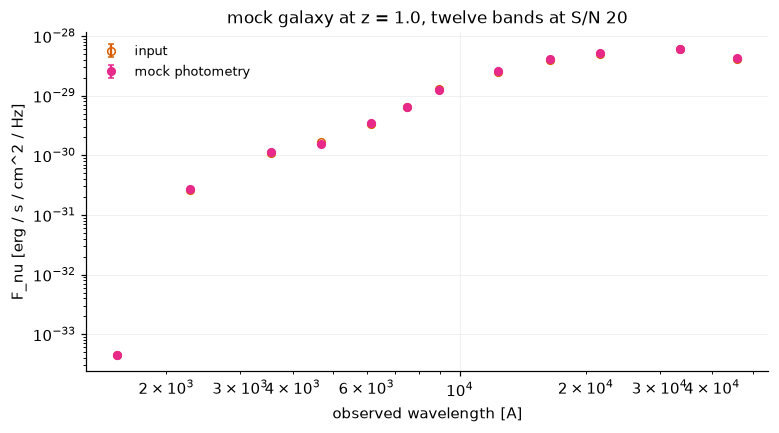

In [6]:
def sed_axes(ax):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("observed wavelength [A]"); ax.set_ylabel("F_nu [erg / s / cm^2 / Hz]")

def plot_photometry(ax, wave_eff, maggies, err, **kw):
    ax.errorbar(wave_eff, np.asarray(maggies) * MAGGIE_TO_CGS, yerr=np.asarray(err) * MAGGIE_TO_CGS,
                fmt="o", ms=5, capsize=2, **kw)

def plot_spectrum(ax, wave, flux, err, label):
    ax.fill_between(wave, flux - err, flux + err, color=COLOUR["band"], lw=0, label=f"{label}, 1 sigma")
    ax.plot(wave, flux, color=COLOUR["data"], lw=0.6, label=label)

fig, ax = plt.subplots(figsize=(8, 4))
plot_photometry(ax, wave_eff, true["phot"], np.zeros(len(FILTERS)), color=COLOUR["truth"], mfc="none", label="input")
plot_photometry(ax, wave_eff, phot_obs, phot_err, color=COLOUR["photometry"], label="mock photometry")
sed_axes(ax); ax.set_title(f"mock galaxy at z = {ZRED}, twelve bands at S/N 20"); ax.legend()
plt.show()

## The fit

`fitSED` builds one Gaussian likelihood per observation, runs nested sampling and writes
`ceridwen_result.h5` and a log into `output_dir`. Its header shows the device and the
precision. The settings below (200 live points, 40 replaced per iteration, 30 slice steps)
are for a demonstration; a science fit uses 500 or more live points. Compare the evidence
only between fits of the same precision and sampler settings (`docs/mac_gpu.md`).

In [7]:
model = model_for(obs, START)

result = fitSED(model, sampler="nested", rng_key=jax.random.PRNGKey(0),
                sampler_kwargs={"num_live": 200, "num_delete": 40, "num_inner_steps": 30},
                output_dir="mock_fit_1_photometry", verbose=True)
print(f"ln Z = {result.log_evidence:.2f} +- {result.log_evidence_err:.2f}, "
      f"{result.n_likelihood_calls:,} likelihood calls, {result.wall_time_s:.0f} s")

ceridwen.fitSED


  Device      : MTL  (mtl:0)


  Precision   : float32  (float32 mode, docs/mac_gpu.md: ln Z and gradients are float32, not comparable bit for bit with a float64 fit)


                ^ Apple GPU (float32)


  Sampler     : nested


...

    Sampler run      :    234.8 s


    Derived mfrac    :    0.294 s


    HDF5 write       :    0.128 s


    Total fitSED     :    235.2 s


ln Z = 281.36 +- 0.26, 127,200 likelihood calls, 232 s


## Recovery

`PostProcess` resamples the run to equal weights and pushes every draw through the forward
model. The same post-processing of the one input parameter set gives the truths of the
derived quantities: the star-formation rates over the last 10 and 100 Myr, the surviving
mass and the ultraviolet magnitude.

In [8]:
def prior_range(prior):
    """The prior's own range: its bounds for a bounded prior, its central 98 % for an unbounded one."""
    bounds = prior.bounds() if callable(prior.bounds) else prior.bounds
    if np.isfinite(float(bounds[0])):
        return tuple(float(x) for x in prior.range)
    return tuple(float(x) for x in prior.tfp_dist().quantile(jnp.array([0.01, 0.99])))

def truth_postprocess(truth_model, windows_myr=(10.0, 100.0)):
    """PostProcess of the one true parameter set: the truths of every derived quantity."""
    truth_result = SamplingResult(
        samples={k: np.asarray(v)[None] for k, v in TRUTH.items()},
        log_evidence=np.nan, log_evidence_err=np.nan, log_weights=np.zeros(1),
        log_likelihoods=np.zeros(1), param_names=list(TRUTH), n_likelihood_calls=0,
        wall_time_s=0.0, sampler_name="truth")
    return PostProcess(truth_model, truth_result, n_samples=1, windows_myr=windows_myr).run()

def prior_postprocess(truth_model, n=1000, windows_myr=(10.0, 100.0), seed=0):
    """PostProcess of ``n`` draws from the priors: the prior, propagated to every derived
    quantity (what the data had to improve on).  Draws from an unbounded prior are kept to
    its central 98 % (the range the figures show): the far tails of a StudentT give
    star-formation histories that overflow float32."""
    keys = jax.random.split(jax.random.PRNGKey(seed), len(PRIORS))
    draws = {}
    for k, key in zip(PRIORS, keys):
        lo, hi = prior_range(PRIORS[k])
        draws[k] = np.clip(np.asarray(PRIORS[k].sample(key, shape=(n,) + np.shape(TRUTH[k]))), lo, hi)
    prior_result = SamplingResult(
        samples=draws, log_evidence=np.nan, log_evidence_err=np.nan, log_weights=np.zeros(n),
        log_likelihoods=np.zeros(n), param_names=list(PRIORS), n_likelihood_calls=0,
        wall_time_s=0.0, sampler_name="prior")
    return PostProcess(truth_model, prior_result, n_samples=n, windows_myr=windows_myr).run()

pp = PostProcess(model, result, n_samples=2000, windows_myr=(10.0, 100.0))
out = pp.run()
out_true = truth_postprocess(truth_model)
out_prior = prior_postprocess(truth_model)

def quantity(o, name):
    """A (N,) array of ``name`` from a PostProcess output: a fitted parameter or a derived one."""
    if name in o["theta"]:
        return np.ravel(np.asarray(o["theta"][name]))
    sfh, uv = o["extras"]["sfh"], o["extras"]["uv"]
    return {"log SFR_10 [M_sun/yr]": np.log10(sfh["sfr10"]),
            "log SFR_100 [M_sun/yr]": np.log10(sfh["sfr100"]),
            "log mass_formed": np.log10(sfh["mass_formed"]),
            "log mass_surviving": np.log10(sfh["mass_surviving"]),
            "mfrac (surviving/formed)": sfh["mfrac"],
            "M_UV": uv["MUV"]}[name]

def recovery_rows(out, out_true, out_prior, names):
    """(label, posterior draws, truth, prior draws) per quantity."""
    rows = []
    for n in names:
        prior_draws = quantity(out_prior, n)
        rows.append((n, quantity(out, n), float(quantity(out_true, n)[0]), prior_draws[np.isfinite(prior_draws)]))
    return rows

def print_recovery(rows):
    print(f"{'quantity':26s} {'truth':>8s}   {'median':>8s}  (16-84 %)      {'prior 16-84 %':>22s}")
    for label, draws, t, prior_draws in rows:
        lo, med, hi = np.percentile(draws, [16, 50, 84])
        p16, p84 = np.percentile(prior_draws, [16, 84])
        print(f"{label:26s} {t:+8.3f}   {med:+8.3f}  (-{med - lo:.3f} / +{hi - med:.3f})   "
              f"[{p16:+8.3f}, {p84:+8.3f}]")

def posterior_panels(rows, priors, ncols=4):
    """One panel per quantity over the range of its prior: the prior (the exact density of a
    fitted parameter, the propagated prior draws of a derived quantity), the posterior
    histogram, its median and 16-84 % band, and the truth."""
    nrows = -(-len(rows) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 2.7 * nrows), squeeze=False)
    for ax, (label, draws, t, prior_draws) in zip(axes.ravel(), rows):
        q16, q50, q84 = np.percentile(draws, [16, 50, 84])
        if label in priors:
            lo, hi = prior_range(priors[label])
            x = np.linspace(lo, hi, 400)
            ax.plot(x, np.exp(np.asarray(priors[label].logpdf(jnp.asarray(x)))),
                    color=COLOUR["prior"], lw=1.3, label="prior")
        else:
            lo, hi = np.percentile(prior_draws, [1, 99])
            lo, hi = min(lo, t, q16), max(hi, t, q84)
            ax.hist(prior_draws, bins=40, range=(lo, hi), density=True, histtype="step",
                    color=COLOUR["prior"], lw=1.3, label="prior (propagated)")
        ax.hist(draws, bins=40, range=(lo, hi), density=True, color=COLOUR["posterior"],
                alpha=0.55, label="posterior")
        ax.axvspan(q16, q84, color=COLOUR["posterior"], alpha=0.18, label="16-84 %")
        ax.axvline(q50, color=COLOUR["posterior"], lw=1.6, label="median")
        ax.axvline(t, color=COLOUR["truth"], lw=2.0, ls="--", label="truth")
        ax.set_xlim(lo, hi); ax.set_yticks([]); ax.grid(False); ax.set_title(label)
    for ax in axes.ravel()[len(rows):]:
        ax.axis("off")
    axes[0, 0].legend(loc="upper left")
    fig.tight_layout()
    return fig

QUANTITIES = ["logmass", "logzsol", "diffuse_tau_kc", "diffuse_dust_index",
              "log SFR_10 [M_sun/yr]", "log SFR_100 [M_sun/yr]", "log mass_surviving", "M_UV"]
rows = recovery_rows(out, out_true, out_prior, QUANTITIES + ["mfrac (surviving/formed)"])
print_recovery(rows)

site-packages/jax/_src/numpy/array_methods.py:125: UserWarning: Explicitly requested dtype float64 requested in astype is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return lax_numpy.astype(self, dtype, copy=copy, device=device)
site-packages/tensorflow_probability/python/internal/backend/jax/ops.py:342: UserWarning: Explicitly requested dtype float64 requested in array is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return np.array(value, dtype=dtype)
site-packages/tensorflow_probability/python/internal/backend/jax/random_generators.py:158: UserWarning: Explicitly requested dtype float64 is not available, and wil

site-packages/tensorflow_probability/python/internal/backend/jax/numpy_array.py:450: UserWarning: Explicitly requested dtype float64 requested in ones is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  lambda shape, dtype=np.float32, name=None, layout=None: np.ones(  # pylint: disable=g-long-lambda


quantity                      truth     median  (16-84 %)               prior 16-84 %
logmass                     +10.300    +10.418  (-0.137 / +0.082)   [  +9.374,  +11.539]
logzsol                      -0.300     -1.314  (-0.481 / +0.759)   [  -1.650,   -0.128]
diffuse_tau_kc               +0.600     +1.134  (-0.386 / +0.157)   [  +0.272,   +1.537]
diffuse_dust_index           -0.500     -0.232  (-0.175 / +0.054)   [  -0.785,   +0.166]
log SFR_10 [M_sun/yr]        +0.534     +0.906  (-0.299 / +0.125)   [  -2.851,   +2.354]
log SFR_100 [M_sun/yr]       +0.384     +0.581  (-0.173 / +0.186)   [  -1.858,   +2.265]
log mass_surviving          +10.086    +10.204  (-0.134 / +0.077)   [  +9.214,  +11.362]
M_UV                        -16.696    -16.739  (-0.032 / +0.035)   [ -21.641,  -11.065]
mfrac (surviving/formed)     +0.611     +0.607  (-0.006 / +0.010)   [  +0.600,   +0.777]


Every panel spans the range of the prior. For a fitted parameter the purple curve is the
prior itself; for a derived quantity it is the prior propagated through the model (1000 prior
draws, post-processed like the posterior), which is what the data had to improve on. The
dashed line is the input value.

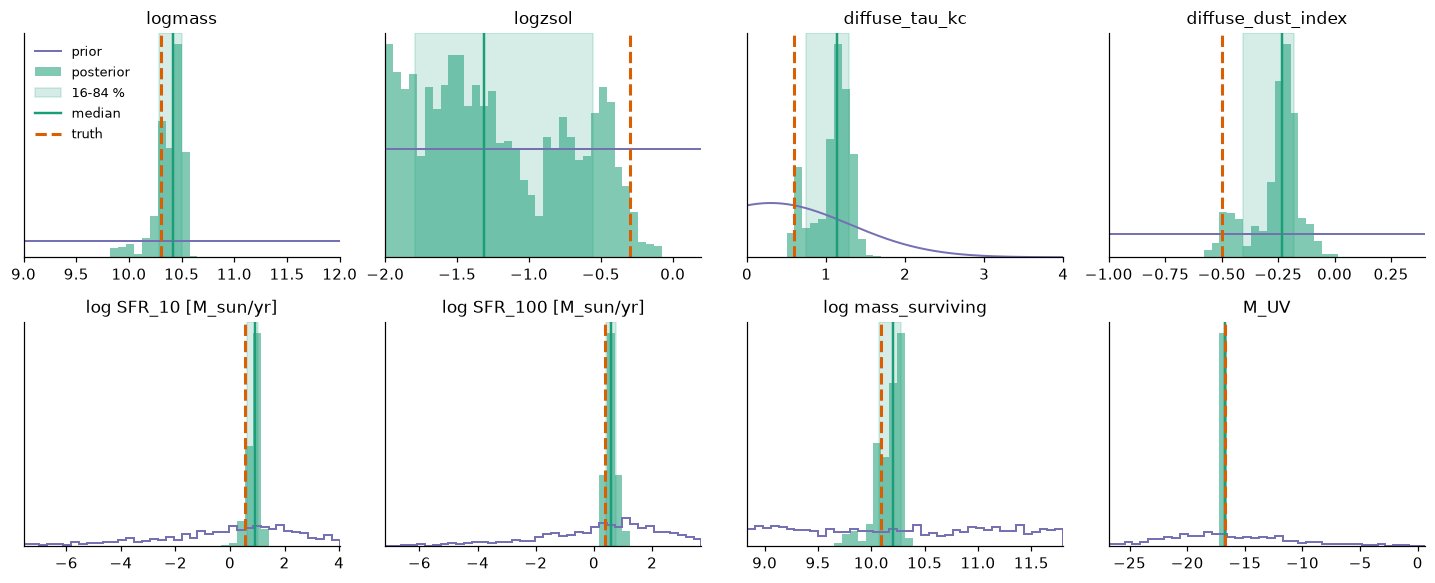

In [9]:
posterior_panels(rows[:8], PRIORS); plt.show()

The star-formation history, bin by bin. Photometry alone constrains the recent bins through
the ultraviolet and the total mass through the near infrared; the middle bins are where the
prior does most of the work.

The fitted parameters together, with the prior on each diagonal. The two-dimensional panels show which parameters trade against each other.

With photometry alone the metallicity and the dust are degenerate: a metal-poor, dustier population has nearly the same colours as a metal-richer, less dusty one. Expect their posteriors to be broad, to miss the input by 2 to 3 sigma, and the metallicity to pile up at the prior's lower edge. That is the data, not the sampler: a spectrum or line fluxes (notebooks 2 to 4) break the degeneracy.

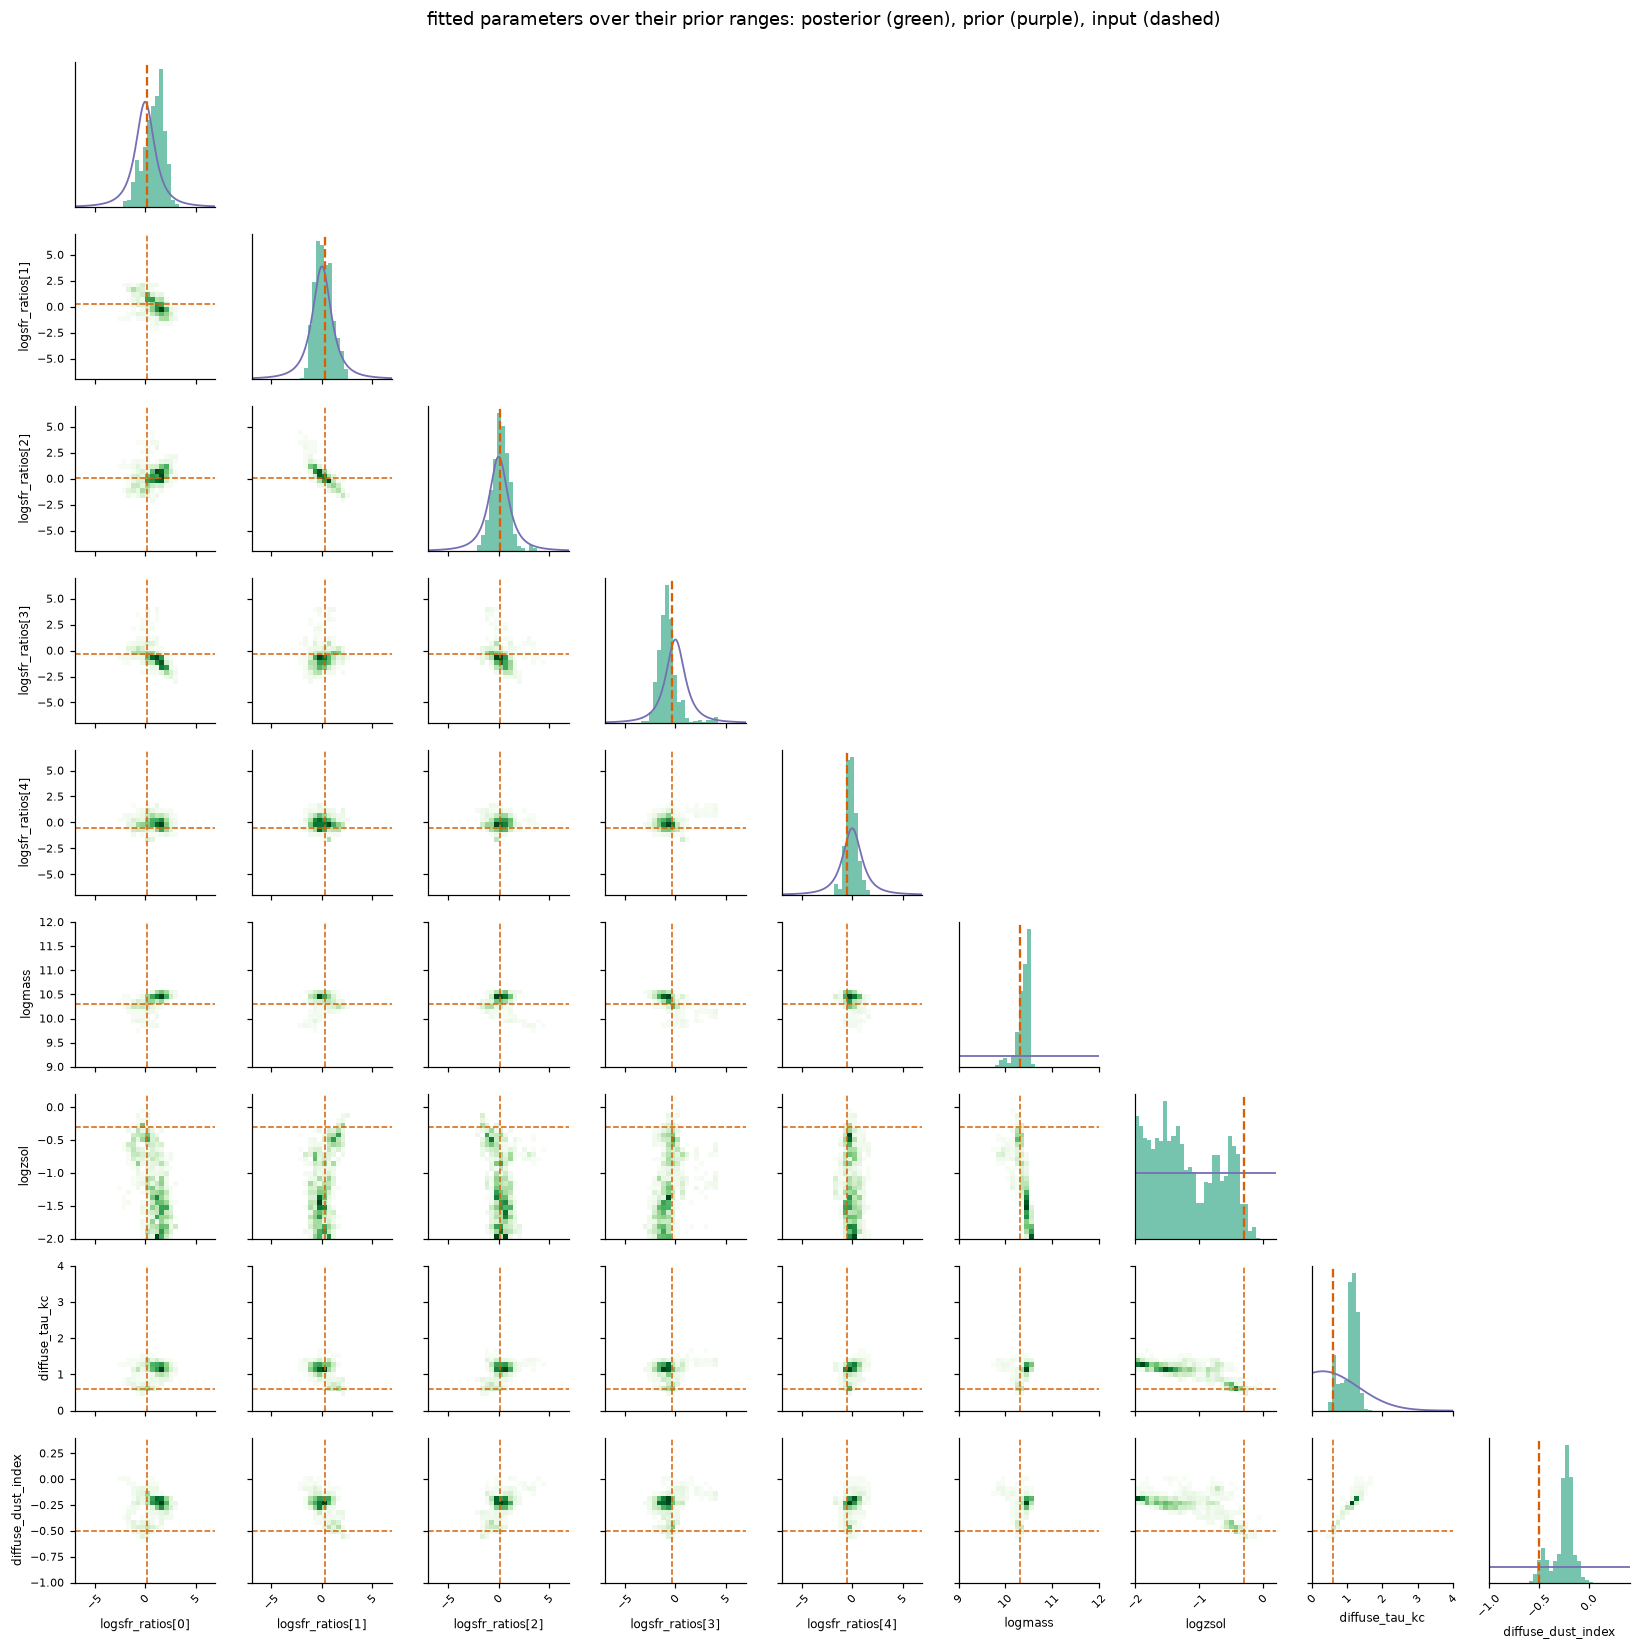

In [10]:
def corner_figure(out, out_prior, priors, truth, names):
    """Corner plot of the fitted parameters: 2-d histograms below the diagonal, and on the
    diagonal the marginal posterior with the prior (density, or propagated draws for a
    vector parameter's components) over the prior's range.  ``names`` are theta keys;
    vector keys are expanded into their components."""
    cols = []
    for k in names:
        v = np.asarray(out["theta"][k]).reshape(len(out["theta"][k]), -1)
        pr = np.asarray(out_prior["theta"][k]).reshape(len(out_prior["theta"][k]), -1)
        tr = np.ravel(np.asarray(truth[k]))
        for j in range(v.shape[1]):
            cols.append((k if v.shape[1] == 1 else f"{k}[{j}]", v[:, j], pr[:, j], float(tr[j]), priors[k]))
    K = len(cols)
    fig, axes = plt.subplots(K, K, figsize=(1.55 * K + 1, 1.55 * K + 1))
    ranges = [prior_range(c[4]) for c in cols]
    for i in range(K):
        for j in range(K):
            ax = axes[i, j]
            ax.grid(False)
            if j > i:
                ax.axis("off"); continue
            if i == j:
                label, draws, pr, t, prior = cols[i]
                lo, hi = ranges[i]
                x = np.linspace(lo, hi, 300)
                ax.plot(x, np.exp(np.asarray(prior.logpdf(jnp.asarray(x)))), color=COLOUR["prior"], lw=1.2)
                ax.hist(draws, bins=35, range=(lo, hi), density=True, color=COLOUR["posterior"], alpha=0.6)
                ax.axvline(t, color=COLOUR["truth"], lw=1.5, ls="--")
                ax.set_xlim(lo, hi); ax.set_yticks([])
            else:
                ax.hist2d(cols[j][1], cols[i][1], bins=30, range=[ranges[j], ranges[i]],
                          cmap="Greens", cmin=1)
                ax.axvline(cols[j][3], color=COLOUR["truth"], lw=1.0, ls="--")
                ax.axhline(cols[i][3], color=COLOUR["truth"], lw=1.0, ls="--")
                ax.set_xlim(ranges[j]); ax.set_ylim(ranges[i])
            if i < K - 1:
                ax.set_xticklabels([])
            else:
                ax.set_xlabel(cols[j][0], fontsize=8); ax.tick_params(axis="x", labelsize=7, rotation=45)
            if j > 0 or i == 0:
                ax.set_yticklabels([])
            else:
                ax.set_ylabel(cols[i][0], fontsize=8); ax.tick_params(axis="y", labelsize=7)
    fig.suptitle("fitted parameters over their prior ranges: posterior (green), prior (purple), input (dashed)", y=1.0)
    fig.tight_layout()
    return fig
corner_figure(out, out_prior, PRIORS, TRUTH, list(PRIORS)); plt.show()

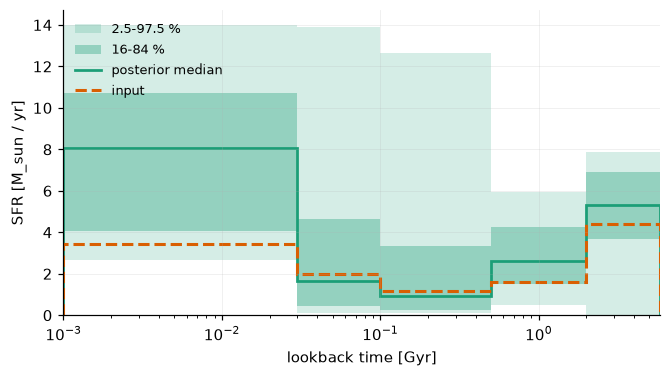

In [11]:
def sfh_figure(out, out_true, lookback_gyr):
    """Input star-formation history against the posterior, per bin, with 16-84 and 2.5-97.5 %
    bands; lookback time on a log axis, the first bin starting at 1 Myr.  PostProcess reports
    the rate at each node; in step mode the model forms a bin at the mean of its two nodes."""
    edges = np.asarray(lookback_gyr, float).copy()
    edges[0] = 1e-3
    per_bin = lambda nodes: 0.5 * (nodes[..., :-1] + nodes[..., 1:])
    sfr = per_bin(np.asarray(out["extras"]["sfh"]["sfr"]))
    q = np.percentile(sfr, [2.5, 16, 50, 84, 97.5], axis=0)
    truth = per_bin(np.asarray(out_true["extras"]["sfh"]["sfr"]))[0]
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.stairs(q[4], edges, baseline=q[0], fill=True, color=COLOUR["posterior"], alpha=0.18, label="2.5-97.5 %")
    ax.stairs(q[3], edges, baseline=q[1], fill=True, color=COLOUR["posterior"], alpha=0.35, label="16-84 %")
    ax.stairs(q[2], edges, color=COLOUR["posterior"], lw=1.8, label="posterior median")
    ax.stairs(truth, edges, color=COLOUR["truth"], lw=2.0, ls="--", label="input")
    ax.set_xscale("log"); ax.set_xlabel("lookback time [Gyr]"); ax.set_ylabel("SFR [M_sun / yr]")
    ax.set_xlim(edges[0], edges[-1]); ax.legend(loc="upper left")
    return fig
sfh_figure(out, out_true, lookback); plt.show()

The posterior-predictive photometry over the data, with residuals in units of the uncertainty.

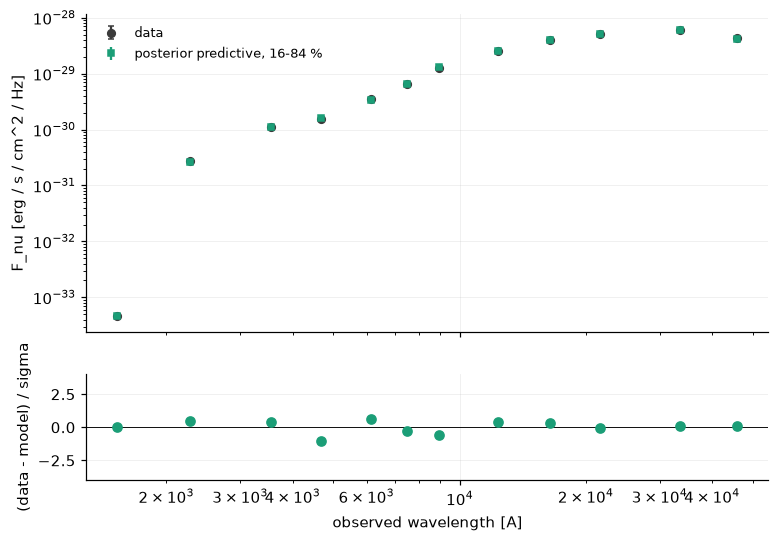

In [12]:
p16, p50, p84 = np.percentile(np.asarray(out["prediction"]["photometry"]["phot"]), [16, 50, 84], axis=0)
fig, (ax, res) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
plot_photometry(ax, wave_eff, phot_obs, phot_err, color=COLOUR["data"], label="data")
ax.errorbar(wave_eff, p50 * MAGGIE_TO_CGS, yerr=[(p50 - p16) * MAGGIE_TO_CGS, (p84 - p50) * MAGGIE_TO_CGS],
            fmt="s", ms=4, color=COLOUR["posterior"], label="posterior predictive, 16-84 %")
sed_axes(ax); ax.set_xlabel(""); ax.legend()
res.axhline(0, color="k", lw=0.6)
res.plot(wave_eff, (phot_obs - p50) / phot_err, "o", color=COLOUR["posterior"])
res.set_xscale("log"); res.set_ylim(-4, 4); res.set_ylabel("(data - model) / sigma"); res.set_xlabel("observed wavelength [A]")
plt.show()